# Credit Card Customer Segmentation with K-Means

**Business context.** A card issuer treats all cardholders the same: the same offers, the same reminders, the same credit reviews.
But a customer who pays in full every month and one who withdraws cash at the limit need very different conversations.
**Segmentation** groups customers by how they actually use the card, so marketing, product and risk teams can act on each group.

**Why K-means?** There is no "right answer" column to predict here; this is **unsupervised** learning. K-means finds groups of customers
whose behaviour is similar, and it is simple to explain: each segment is summarised by its average customer (its *centre*).

**Deliverable.** This notebook builds the segments and exports clean tables for an **interactive Power BI report**
(see `powerbi/POWERBI_BUILD_GUIDE.md`).

**Dataset.** *Credit Card Dataset for Clustering* (Kaggle, Arjun Bhasin): 8,950 active cardholders, 18 behavioural columns summarising 6 months of use.
The currency is not stated; amounts are treated as US dollars.

**Outline**
1. Setup and data loading
2. Data dictionary and data-quality checks
3. Feature selection and engineering
4. Transforming skewed amounts and scaling
5. How K-means works
6. Choosing the number of segments
7. Fitting the final model and checking stability
8. Visualising segments with PCA
9. Segment profiles and personas
10. Why six segments rather than five
11. Exporting tables for Power BI
12. Limitations and model ownership

> **How to read this notebook:** each section starts with *what* the step does and *why*.
> Code cells have inline comments (lines starting with `#`) explaining each line.

## 1. Setup and data loading

| Library | Used for |
|---|---|
| `pandas`, `numpy` | Data tables and maths |
| `matplotlib` | Charts |
| `scikit-learn` | Scaling, K-means, silhouette score, PCA, adjusted Rand index |

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42
FIG_DIR = "../reports/figures"
EXPORT_DIR = "../powerbi/data"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(EXPORT_DIR, exist_ok=True)

In [2]:
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "CC GENERAL.csv")
URL = "https://raw.githubusercontent.com/rohitdileep/Credit-Card-Segmentation-using-Kmeans/main/CC_GENERAL.csv"

if not os.path.exists(CSV_PATH):        # download only if the file isn't already in data/
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_PATH)

raw = pd.read_csv(CSV_PATH)
print(raw.shape)
raw.head()

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.90,0.82,95.40,0.00,95.40,0.00,0.17,0.00,0.08,0.00,0,2,"1,000.00",201.80,139.51,0.00,12
1,C10002,"3,202.47",0.91,0.00,0.00,0.00,"6,442.95",0.00,0.00,0.00,0.25,4,0,"7,000.00","4,103.03","1,072.34",0.22,12
2,C10003,"2,495.15",1.00,773.17,773.17,0.00,0.00,1.00,1.00,0.00,0.00,0,12,"7,500.00",622.07,627.28,0.00,12
3,C10004,"1,666.67",0.64,"1,499.00","1,499.00",0.00,205.79,0.08,0.08,0.00,0.08,1,1,"7,500.00",0.00,NaN,0.00,12
4,C10005,817.71,1.00,16.00,16.00,0.00,0.00,0.08,0.08,0.00,0.00,0,1,"1,200.00",678.33,244.79,0.00,12


## 2. Data dictionary and data-quality checks

| Column | Meaning |
|---|---|
| `CUST_ID` | Customer identifier |
| `BALANCE` | Balance owed |
| `BALANCE_FREQUENCY` | How often the balance was updated (0–1) |
| `PURCHASES` | Total purchases = `ONEOFF_PURCHASES` + `INSTALLMENTS_PURCHASES` |
| `CASH_ADVANCE` | Cash withdrawn on the card |
| `PURCHASES_FREQUENCY`, `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY`, `CASH_ADVANCE_FREQUENCY` | Share of months with that activity (0–1) |
| `PURCHASES_TRX`, `CASH_ADVANCE_TRX` | Number of transactions |
| `CREDIT_LIMIT` | Credit limit |
| `PAYMENTS`, `MINIMUM_PAYMENTS` | Amount paid; minimum payments made |
| `PRC_FULL_PAYMENT` | Share of months the full balance was paid (0–1) |
| `TENURE` | Months of history (6–12) |

In [3]:
print("Missing values:\n", raw.isna().sum()[lambda s: s > 0].to_string())
print("\nDuplicate customer IDs:", raw["CUST_ID"].duplicated().sum())
print("Cash-advance frequency above 1 (impossible for a share):", (raw["CASH_ADVANCE_FREQUENCY"] > 1).sum())
print("Purchases not equal to one-off + instalments (difference > 1):",
      ((raw["PURCHASES"] - raw["ONEOFF_PURCHASES"] - raw["INSTALLMENTS_PURCHASES"]).abs() > 1).sum())
print("Missing minimum payments where payments are 0:", (raw["MINIMUM_PAYMENTS"].isna() & (raw["PAYMENTS"] == 0)).sum())
print("\nTenure (months of history):", raw["TENURE"].value_counts().sort_index().to_dict())

Missing values:
 CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313

Duplicate customer IDs: 0
Cash-advance frequency above 1 (impossible for a share): 8
Purchases not equal to one-off + instalments (difference > 1): 19
Missing minimum payments where payments are 0: 240

Tenure (months of history): {6: 204, 7: 190, 8: 196, 9: 175, 10: 236, 11: 365, 12: 7584}


**Data-quality findings**

| Issue | Detail | Decision |
|---|---|---|
| `CREDIT_LIMIT` missing | 1 customer | Drop the row: utilization can't be computed |
| `MINIMUM_PAYMENTS` missing | 313 customers, mostly with no payments at all | Not used for clustering, so no imputation needed; kept as blank in the Power BI export |
| `CASH_ADVANCE_FREQUENCY` > 1 | 8 customers, up to 1.5 | Cap at 1 (it's a share of months) |
| Purchases ≠ one-off + instalments | 19 customers, small differences | Leave as is; the components are used, not the total |
| `TENURE` | 85% have 12 months | Not used as a feature: nearly constant, and the frequencies already account for it |

In [4]:
df = raw.dropna(subset=["CREDIT_LIMIT"]).reset_index(drop=True)
df["CASH_ADVANCE_FREQUENCY"] = df["CASH_ADVANCE_FREQUENCY"].clip(upper=1)
print(f"{len(df):,} customers after cleaning")

8,949 customers after cleaning


## 3. Feature selection and engineering

Clustering groups customers by *every* feature it is given, so the feature list decides what the segments mean. The aim is to cover the main
dimensions of card behaviour once each, without near-duplicates that would give one dimension double weight.

| Dimension | Features |
|---|---|
| How much they owe | `BALANCE` |
| How they buy | `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `PURCHASES_FREQUENCY` |
| Cash use | `CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY` |
| Capacity | `CREDIT_LIMIT` |
| Repayment | `PAYMENTS`, `PRC_FULL_PAYMENT` |
| Pressure on the limit | **`utilization` = BALANCE ÷ CREDIT_LIMIT** (new; capped at 1.5) |

**Left out:** `PURCHASES` (it's the sum of the two purchase types), the transaction counts (they duplicate amounts and frequencies),
the one-off and instalment frequencies (they duplicate `PURCHASES_FREQUENCY`), `BALANCE_FREQUENCY` (mostly 1), `MINIMUM_PAYMENTS` (missing values) and `TENURE`.

In [5]:
df["utilization"] = (df["BALANCE"] / df["CREDIT_LIMIT"]).clip(upper=1.5)
print(f"Customers over their limit (utilization > 1): {(df['BALANCE'] > df['CREDIT_LIMIT']).sum()}")
LOG_AMOUNTS = ["BALANCE", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
SHARES = ["PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PRC_FULL_PAYMENT", "utilization"]

Customers over their limit (utilization > 1): 227


## 4. Transforming skewed amounts and scaling

**Why transform?** K-means measures distance between customers. The amounts are extremely skewed: most customers have small values and a few have huge ones.
Left as they are, the few extreme customers would dominate the distances, and the segments would mostly separate "huge" from "everyone else".

**Step 1: log(1 + x)** compresses large values (1,000 → 6.9; 10,000 → 9.2) and maps 0 to 0, which matters because many customers have zero cash advances or zero purchases.

**Step 2: standardise** every feature to mean 0 and standard deviation 1, so a feature measured in dollars doesn't outweigh one measured as a share between 0 and 1.

In [6]:
feats = pd.DataFrame(index=df.index)
for c in LOG_AMOUNTS:
    feats[f"log_{c.lower()}"] = np.log1p(df[c])              # log(1 + x)
feats["purchases_frequency"] = df["PURCHASES_FREQUENCY"]
feats["cash_advance_frequency"] = df["CASH_ADVANCE_FREQUENCY"]
feats["prc_full_payment"] = df["PRC_FULL_PAYMENT"]
feats["utilization"] = df["utilization"]

# Skewness before and after the log (0 = symmetric; above 1 = strongly skewed)
print(pd.DataFrame({"skew_before": df[LOG_AMOUNTS].skew().values,
                    "skew_after_log": feats[[f"log_{c.lower()}" for c in LOG_AMOUNTS]].skew().values},
                   index=LOG_AMOUNTS).round(2))

scaler = StandardScaler()
X = scaler.fit_transform(feats)      # each column now has mean 0, standard deviation 1
FEATURES = list(feats.columns)

                        skew_before  skew_after_log
BALANCE                        2.39           -0.86
ONEOFF_PURCHASES              10.04            0.19
INSTALLMENTS_PURCHASES         7.30           -0.03
CASH_ADVANCE                   5.17            0.26
CREDIT_LIMIT                   1.52           -0.10
PAYMENTS                       5.91           -1.78


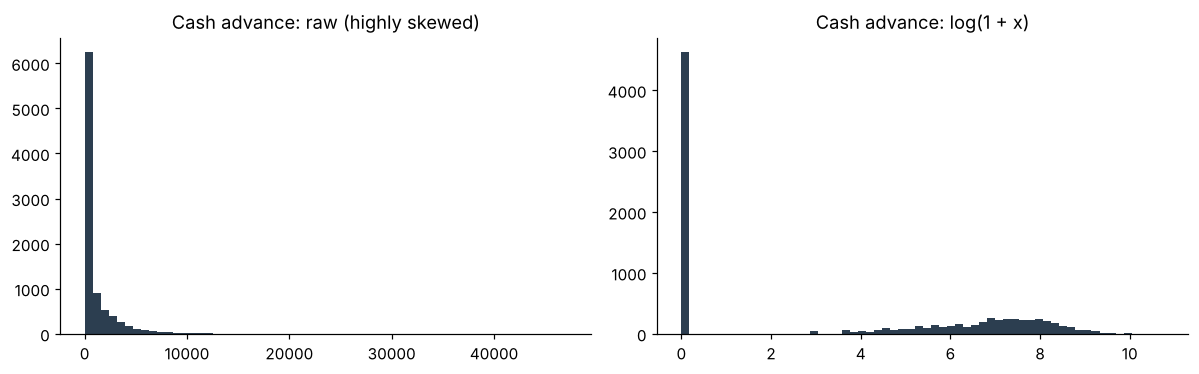

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["CASH_ADVANCE"], bins=60, color="#2C3E50"); axes[0].set_title("Cash advance: raw (highly skewed)")
axes[1].hist(feats["log_cash_advance"], bins=60, color="#2C3E50"); axes[1].set_title("Cash advance: log(1 + x)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_log_transform.png", dpi=120, bbox_inches="tight"); plt.show()

The log doesn't make every feature symmetric: cash advances still pile up at zero, because about half of customers never take one.
That's real behaviour, not a problem to fix; K-means will simply tend to separate cash users from non-users.

## 5. How K-means works

1. Choose *k*, the number of segments.
2. Place *k* starting centres (scikit-learn uses the *k-means++* method to spread them out).
3. **Assign** each customer to the nearest centre (straight-line, or Euclidean, distance across the 10 scaled features).
4. **Move** each centre to the average of the customers assigned to it.
5. Repeat steps 3–4 until the assignments stop changing.

The result minimises **inertia**: the sum of squared distances from each customer to their segment's centre.
Because the starting centres are random, the algorithm is run 20 times (`n_init=20`) and the best result is kept.

## 6. Choosing the number of segments

K-means can't choose *k* itself. Two standard guides:
- **Elbow method:** plot inertia against *k* and look for the "elbow", where adding segments stops helping much.
- **Silhouette score:** for each customer, compare how close they are to their own segment with how close they are to the nearest other segment.

**Silhouette, step by step** for customer *i*:
- *a* = average distance to the other customers in the **same** segment
- *b* = average distance to the customers in the **nearest other** segment
- s = (b − a) ÷ max(a, b): close to 1 = clearly in the right segment; near 0 = on a boundary; negative = probably in the wrong one

The overall score is the average *s* across all customers.

In [8]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                 "smallest_segment": np.bincount(km.labels_).min()})
k_table = pd.DataFrame(rows)
k_table

,k,inertia,silhouette,smallest_segment
0,2,"66,194.56",0.25,4128
1,3,"56,383.29",0.22,2895
2,4,"49,751.21",0.23,1402
3,5,"45,096.05",0.23,1314
4,6,"41,414.76",0.22,1071
5,7,"38,668.52",0.23,260
6,8,"36,010.57",0.23,261
7,9,"33,479.27",0.21,263
8,10,"31,739.80",0.22,263


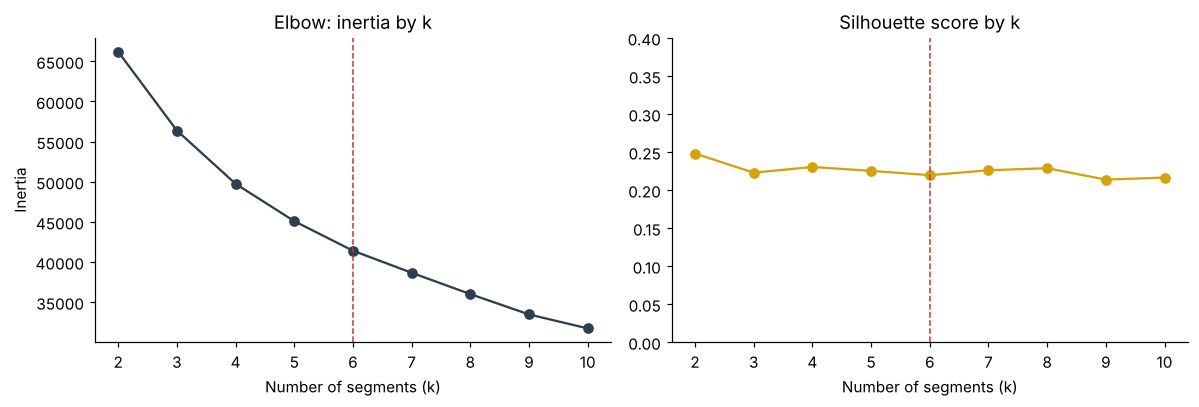

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_table["k"], k_table["inertia"], "o-", color="#2C3E50"); axes[0].set_title("Elbow: inertia by k")
axes[0].set_xlabel("Number of segments (k)"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_table["k"], k_table["silhouette"], "o-", color="#D4A20B"); axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("Number of segments (k)"); axes[1].set_ylim(0, 0.4)
for ax in axes: ax.axvline(6, color="#C0392B", ls="--", lw=1)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_choosing_k.png", dpi=120, bbox_inches="tight"); plt.show()

In [10]:
# Silhouette by hand for one customer, using the 6-segment solution
km6 = KMeans(n_clusters=6, n_init=20, random_state=RANDOM_STATE).fit(X)
i = 0
dist = np.linalg.norm(X - X[i], axis=1)                       # distance from customer i to everyone
own = km6.labels_ == km6.labels_[i]
a = dist[own & (np.arange(len(X)) != i)].mean()
b = min(dist[km6.labels_ == c].mean() for c in range(6) if c != km6.labels_[i])
print(f"Customer {df['CUST_ID'][i]}: a = {a:.3f} (own segment), b = {b:.3f} (nearest other segment)")
print(f"s = (b - a) / max(a, b) = ({b:.3f} - {a:.3f}) / {max(a, b):.3f} = {(b - a) / max(a, b):.3f}")

Customer C10001: a = 2.732 (own segment), b = 3.792 (nearest other segment)
s = (b - a) / max(a, b) = (3.792 - 2.732) / 3.792 = 0.280


**There is no clear answer, and that's normal.** The inertia curve bends gradually with no sharp elbow, and the silhouette score is low (0.22–0.25) and almost flat from 3 to 10 segments.
Real customers sit on a continuum; they don't form neat, separate clouds. The statistics rule out very large *k* (tiny segments appear from k = 7) but don't pick a winner.

So the choice is made on **business usefulness**, then checked for **stability**:
- Each segment should be large enough to act on (here, at least 10% of customers).
- Each should suggest a *different* action for marketing or risk.
- The segments should come out the same when the algorithm is re-run.

**Six segments** meets all three (Section 10 shows what six adds over five).

## 7. Fitting the final model and checking stability

**Stability check.** If the segments are real structure rather than an accident of the random start, re-running K-means with different starting points
(and on random 80% subsets of customers) should reproduce them. Agreement is measured with the **adjusted Rand index (ARI)**:
1 = identical groupings, 0 = no better than chance.

In [11]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
labels = kmeans.labels_

# 1) Different random starts
ari_seeds = [adjusted_rand_score(labels, KMeans(K, n_init=20, random_state=s).fit(X).labels_) for s in range(1, 6)]
# 2) Refit on random 80% subsets; compare on the customers in each subset
rng = np.random.default_rng(RANDOM_STATE)
ari_subsets = []
for _ in range(5):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    sub = KMeans(K, n_init=20, random_state=RANDOM_STATE).fit(X[idx])
    ari_subsets.append(adjusted_rand_score(labels[idx], sub.labels_))
print("ARI vs different random starts:", np.round(ari_seeds, 3))
print("ARI vs refits on 80% subsets:  ", np.round(ari_subsets, 3))

ARI vs different random starts: [0.997 0.989 0.997 1.    0.987]
ARI vs refits on 80% subsets:   [0.974 0.971 0.982 0.972 0.987]


ARI values close to 1 mean the segments are **stable**: the same customers end up together however the algorithm starts, and even when 20% of customers are left out.
The low silhouette says the segments have fuzzy edges; the high ARI says their cores are consistent. Both are worth stating.

## 8. Visualising segments with PCA

The customers live in 10 dimensions, which can't be drawn. **Principal component analysis (PCA)** finds the two directions that capture
the most variation, so the segments can be plotted on a flat chart. PCA is used only for the picture; the segments were found in all 10 dimensions.

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
print(f"Variance explained: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}, "
      f"together {pca.explained_variance_ratio_.sum():.1%}")
# Which features drive each component?
pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2)

Variance explained: PC1 34.2%, PC2 21.9%, together 56.1%


,PC1,PC2
log_balance,0.38,0.38
log_oneoff_purchases,-0.11,0.41
log_installments_purchases,-0.32,0.34
log_cash_advance,0.45,0.05
log_credit_limit,0.03,0.41
log_payments,0.08,0.49
purchases_frequency,-0.34,0.39
cash_advance_frequency,0.41,0.10
prc_full_payment,-0.32,0.06
utilization,0.39,0.10


**Reading the components** (the loadings above: large positive or negative numbers drive a component).
- **PC1 contrasts two ways of using the card.** Cash advances, cash-advance frequency, utilization and balance push it up; purchase frequency, instalment purchases and paying in full push it down.
  So the right of the chart is "borrowing and cash", the left is "buying and paying off".
- **PC2 is overall activity and size**: payments, credit limit, one-off purchases, purchase frequency and balance all push it up together.
Two dimensions keep a little over half of the variation, so segments that look overlapping on the chart can still be separate in the full 10 dimensions.

## 9. Segment profiles and personas

**Naming segments.** K-means numbers clusters arbitrarily (0–5), and the numbers can change between software versions.
Names are therefore assigned by **rules on each segment's median behaviour**, applied in order:
1. Highest full-payment rate → **Transactors**
2. Highest utilization → **Near-limit revolvers**
3. Most cash advances relative to purchases → **Cash-advance reliant**
4. Smallest balance → **Light users**
5. Highest cash advances among the rest → **Heavy all-rounders**
6. The remaining segment → **High-limit spenders**

In [13]:
df["seg"] = labels
med = df.groupby("seg")[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PRC_FULL_PAYMENT", "utilization"]].median()
names, left = {}, list(med.index)
def take(seg, name):
    names[seg] = name; left.remove(seg)
take(med.loc[left, "PRC_FULL_PAYMENT"].idxmax(), "Transactors")
take(med.loc[left, "utilization"].idxmax(), "Near-limit revolvers")
take((med.loc[left, "CASH_ADVANCE"] - med.loc[left, "PURCHASES"]).idxmax(), "Cash-advance reliant")
take(med.loc[left, "BALANCE"].idxmin(), "Light users")
take(med.loc[left, "CASH_ADVANCE"].idxmax(), "Heavy all-rounders")
take(left[0], "High-limit spenders")

ORDER = ["Transactors", "High-limit spenders", "Light users", "Heavy all-rounders", "Near-limit revolvers", "Cash-advance reliant"]
COLORS = ["#2E7D5B", "#2C3E50", "#95A5A6", "#D4A20B", "#B9603A", "#7B5EA7"]
df["segment_name"] = df["seg"].map(names)
df["segment_id"] = df["segment_name"].map({n: i + 1 for i, n in enumerate(ORDER)})

PROFILE_COLS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT",
                "PAYMENTS", "utilization", "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PRC_FULL_PAYMENT"]
profile = df.groupby("segment_name")[PROFILE_COLS].median().reindex(ORDER)
profile.insert(0, "customers", df["segment_name"].value_counts().reindex(ORDER))
profile.insert(1, "share", profile["customers"] / len(df))
profile

,customers,share,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,utilization,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT
segment_name,,,,,,,,,,,,,
Transactors,1239,0.14,80.36,837.43,32.71,469.00,0.00,"4,000.00","1,034.73",0.02,0.92,0.00,0.88
High-limit spenders,1532,0.17,869.93,"1,535.01",891.28,419.37,0.00,"6,000.00","1,513.96",0.18,0.83,0.00,0.00
Light users,1551,0.17,29.36,190.26,0.00,92.16,0.00,"2,500.00",220.00,0.01,0.33,0.00,0.00
Heavy all-rounders,1084,0.12,"3,121.72","1,044.38",514.62,378.01,"2,148.39","6,000.00","2,036.26",0.58,0.83,0.33,0.00
Near-limit revolvers,1153,0.13,"1,117.68",450.00,71.80,168.00,0.00,"1,500.00",619.06,0.86,0.58,0.00,0.00
Cash-advance reliant,2390,0.27,"1,631.03",0.00,0.00,0.00,"1,357.17","3,000.00",845.49,0.64,0.00,0.25,0.00


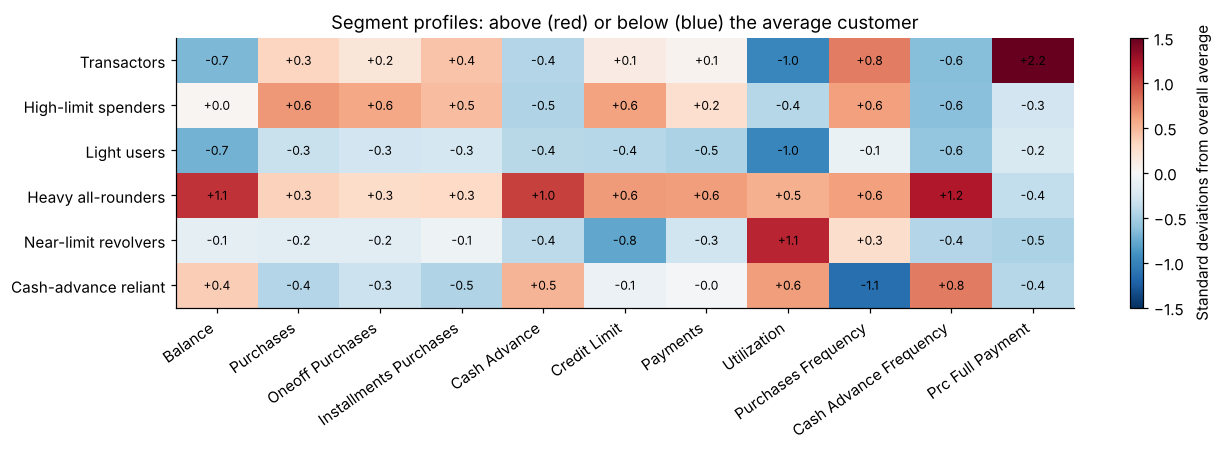

In [14]:
# Heatmap: how far each segment's average is from the overall average, in standard deviations (z-score)
z = pd.DataFrame({c: (df.groupby("segment_name")[c].mean() - df[c].mean()) / df[c].std() for c in PROFILE_COLS}).reindex(ORDER)
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(PROFILE_COLS)), [c.replace("_", " ").title() for c in PROFILE_COLS], rotation=35, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
for r in range(z.shape[0]):
    for c in range(z.shape[1]):
        ax.text(c, r, f"{z.values[r, c]:+.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Standard deviations from overall average")
ax.set_title("Segment profiles: above (red) or below (blue) the average customer")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_profile_heatmap.png", dpi=120, bbox_inches="tight"); plt.show()

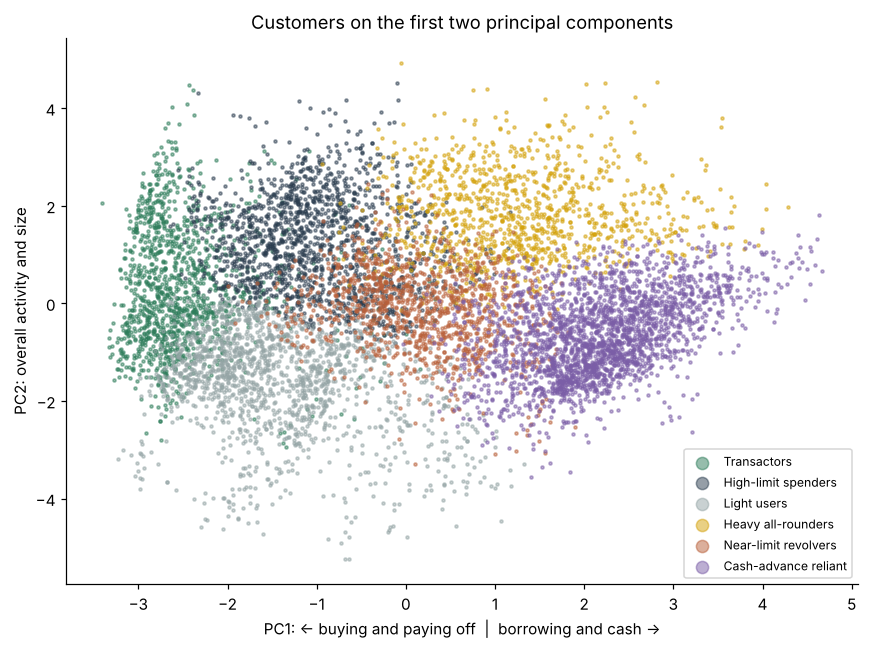

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(ORDER, COLORS):
    m = (df["segment_name"] == name).values
    ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, color=color, label=name)
ax.set_xlabel("PC1: ← buying and paying off  |  borrowing and cash →"); ax.set_ylabel("PC2: overall activity and size")
ax.legend(markerscale=4, fontsize=8, loc="best"); ax.set_title("Customers on the first two principal components")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_pca_segments.png", dpi=120, bbox_inches="tight"); plt.show()

**The six personas**

| Segment | Share | What they do | Suggested action | Risk view |
|---|---|---|---|---|
| **Transactors** | 14% | Buy often, pay in full almost every month, carry almost no balance | Rewards and premium upgrades; keep them through value, since they generate little interest | Low |
| **High-limit spenders** | 17% | High limits and the largest purchases, but use little of their limit | Spend-based offers, instalment plans for big purchases; prioritise retention | Low to moderate |
| **Light users** | 17% | Small balances, occasional small purchases | Activation (first-purchase bonus, digital wallet); review dormant accounts | Low |
| **Heavy all-rounders** | 12% | Highest balances: buy, take cash and carry a balance | Most profitable but exposed; balance-transfer and instalment offers, close monitoring | Moderate to high |
| **Near-limit revolvers** | 13% | Low limits used almost fully (median 86%), revolving every month | Early-warning monitoring, payment-plan outreach; review before any limit increase | High |
| **Cash-advance reliant** | 27% | Rarely buy; withdraw cash at high interest | Offer lower-cost credit (personal loan, overdraft); watch for financial stress | High |

The largest single group, more than a quarter of customers, uses the card mainly for **cash**: a group worth looking at from both a revenue and a customer-wellbeing angle.

## 10. Why six segments rather than five

The silhouette score slightly favours five. Comparing the two solutions shows what the sixth segment adds:

In [16]:
km5 = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X)
cross = pd.crosstab(df["segment_name"], km5.labels_, rownames=["6-segment solution"], colnames=["5-segment cluster"]).reindex(ORDER)
cross

5-segment cluster,0,1,2,3,4
6-segment solution,,,,,
Transactors,0,3,1235,1,0
High-limit spenders,2,1312,99,32,87
Light users,0,42,6,1502,1
Heavy all-rounders,67,0,1,0,1016
Near-limit revolvers,94,822,2,34,201
Cash-advance reliant,2374,2,0,5,9


In [17]:
# Where do the near-limit revolvers go in the 5-segment solution, and what do they look like there?
nl = df["segment_name"] == "Near-limit revolvers"
main5 = pd.Series(km5.labels_[nl]).value_counts().index[0]
merged = km5.labels_ == main5
print(f"In the 5-segment solution, {(km5.labels_[nl] == main5).mean():.0%} of near-limit revolvers join cluster {main5}, "
      f"which then has {merged.sum():,} customers.")
print(f"Median utilization: near-limit revolvers {df.loc[nl, 'utilization'].median():.0%}, "
      f"the rest of that merged cluster {df.loc[merged & ~nl.values, 'utilization'].median():.0%}")

In the 5-segment solution, 71% of near-limit revolvers join cluster 1, which then has 2,181 customers.
Median utilization: near-limit revolvers 86%, the rest of that merged cluster 21%


With five segments, the near-limit revolvers are mostly absorbed into a broader group of customers who use far less of their limit.
For a **risk team**, customers at 86% utilization on low limits are exactly the ones to watch, so a solution that hides them is less useful,
even if its silhouette score is a fraction higher. This is the kind of judgement unsupervised learning needs: statistics narrow the options, the business use decides.

## 11. Exporting tables for Power BI

The report uses a small **star schema**: one fact table of customers, and dimension tables describing segments and metrics.

| Table | Grain | Key columns |
|---|---|---|
| `customers.csv` | One row per customer | `customer_id`, `segment_id`, behaviour columns, flags, `pca_1`, `pca_2`, `distance_to_centre` |
| `segments.csv` | One row per segment | `segment_id`, name, description, recommended action, risk view, colour, size |
| `metrics.csv` | One row per profile metric | `metric_id`, label, description, unit |
| `segment_profile.csv` | One row per segment × metric | `segment_id`, `metric_id`, mean, median, overall mean, z-score |
| `k_selection.csv` | One row per k tried | `k`, inertia, silhouette |

Relationships: `customers[segment_id]` → `segments[segment_id]`; `segment_profile[segment_id]` → `segments[segment_id]`; `segment_profile[metric_id]` → `metrics[metric_id]`.

In [18]:
from datetime import date
PERSONAS = {
    "Transactors": ("Buy often and pay the full balance almost every month; carry almost no balance.",
                    "Rewards and premium card upgrades; little interest income, so keep them through value, not price.", "Low"),
    "High-limit spenders": ("High credit limits and the largest purchases, but use only a small part of their limit.",
                            "Spend-based offers and instalment plans for large purchases; good candidates for retention efforts.", "Low to moderate"),
    "Light users": ("Small balances and occasional small purchases; the card isn't their main one.",
                    "Activation campaigns (first-purchase bonus, digital wallet set-up); review dormant accounts.", "Low"),
    "Heavy all-rounders": ("The highest balances: they buy regularly, take cash advances and carry a balance.",
                           "Most profitable but exposed; balance-transfer and instalment offers, with close credit monitoring.", "Moderate to high"),
    "Near-limit revolvers": ("Low limits used almost to the maximum, carrying a balance month to month.",
                             "Early-warning monitoring and payment-plan outreach; review before any limit increase.", "High"),
    "Cash-advance reliant": ("Rarely buy anything; use the card mainly to withdraw cash, at high interest.",
                             "Offer lower-cost alternatives (personal loan, overdraft); monitor for financial stress.", "High"),
}

customers = pd.DataFrame({
    "customer_id": df["CUST_ID"], "segment_id": df["segment_id"],
    "balance": df["BALANCE"].round(2), "purchases": df["PURCHASES"].round(2),
    "oneoff_purchases": df["ONEOFF_PURCHASES"].round(2), "installment_purchases": df["INSTALLMENTS_PURCHASES"].round(2),
    "cash_advance": df["CASH_ADVANCE"].round(2), "credit_limit": df["CREDIT_LIMIT"].round(2),
    "payments": df["PAYMENTS"].round(2), "minimum_payments": df["MINIMUM_PAYMENTS"].round(2),
    "utilization": df["utilization"].round(4), "purchases_frequency": df["PURCHASES_FREQUENCY"].round(4),
    "cash_advance_frequency": df["CASH_ADVANCE_FREQUENCY"].round(4), "full_payment_rate": df["PRC_FULL_PAYMENT"].round(4),
    "purchase_transactions": df["PURCHASES_TRX"], "cash_advance_transactions": df["CASH_ADVANCE_TRX"],
    "tenure_months": df["TENURE"],
    "uses_cash_advance": (df["CASH_ADVANCE"] > 0).astype(int),               # flag: any cash advance
    "usually_pays_in_full": (df["PRC_FULL_PAYMENT"] >= 0.75).astype(int),    # flag: pays in full 75%+ of months
    "pca_1": np.round(P[:, 0], 4), "pca_2": np.round(P[:, 1], 4),
    "distance_to_centre": np.round(np.linalg.norm(X - kmeans.cluster_centers_[labels], axis=1), 4),
})

segments = pd.DataFrame({"segment_id": range(1, K + 1), "segment_name": ORDER,
                         "description": [PERSONAS[n][0] for n in ORDER], "recommended_action": [PERSONAS[n][1] for n in ORDER],
                         "risk_view": [PERSONAS[n][2] for n in ORDER], "color_hex": COLORS,
                         "customers": [int((df["segment_name"] == n).sum()) for n in ORDER]})

METRICS = [("BALANCE", "Balance", "Average balance over the period", "amount"),
           ("PURCHASES", "Purchases", "Total purchases over the period", "amount"),
           ("ONEOFF_PURCHASES", "One-off purchases", "Purchases paid in one go", "amount"),
           ("INSTALLMENTS_PURCHASES", "Instalment purchases", "Purchases paid in instalments", "amount"),
           ("CASH_ADVANCE", "Cash advances", "Cash withdrawn on the card", "amount"),
           ("CREDIT_LIMIT", "Credit limit", "Credit limit", "amount"),
           ("PAYMENTS", "Payments", "Total payments made", "amount"),
           ("utilization", "Utilization", "Balance ÷ credit limit", "percent"),
           ("PURCHASES_FREQUENCY", "Purchase frequency", "Share of months with purchases", "percent"),
           ("CASH_ADVANCE_FREQUENCY", "Cash-advance frequency", "Share of months with a cash advance", "percent"),
           ("PRC_FULL_PAYMENT", "Full-payment rate", "Share of months the full balance was paid", "percent"),
           ("PURCHASES_TRX", "Purchase transactions", "Number of purchase transactions", "count")]
metrics = pd.DataFrame([{"metric_id": i + 1, "metric": m[1], "description": m[2], "unit": m[3]} for i, m in enumerate(METRICS)])

rows = []
for i, (col, *_rest) in enumerate(METRICS):
    overall_mean, overall_sd = df[col].mean(), df[col].std()
    for sid, g in df.groupby("segment_id"):
        rows.append({"segment_id": sid, "metric_id": i + 1, "segment_mean": g[col].mean(), "segment_median": g[col].median(),
                     "overall_mean": overall_mean, "z_score": (g[col].mean() - overall_mean) / overall_sd})
segment_profile = pd.DataFrame(rows).round(4)

for name, table in {"customers": customers, "segments": segments, "metrics": metrics,
                    "segment_profile": segment_profile, "k_selection": k_table.drop(columns="smallest_segment").round(4)}.items():
    table.to_csv(os.path.join(EXPORT_DIR, f"{name}.csv"), index=False)
    print(f"{name + '.csv':22s} {len(table):>6,} rows x {table.shape[1]} columns")

customers.csv           8,949 rows x 22 columns
segments.csv                6 rows x 7 columns
metrics.csv                12 rows x 4 columns
segment_profile.csv        72 rows x 6 columns
k_selection.csv             9 rows x 3 columns


## 12. Limitations and model ownership

**Limitations**
- **One snapshot:** six months of behaviour from one unnamed issuer, with no dates, so segments can't yet be tracked over time.
- **No outcome data:** there is no profitability, default or churn information, so the risk views and actions are hypotheses to test, not proven results.
- **Fuzzy boundaries:** the low silhouette score means many customers sit between segments. `distance_to_centre` in the export flags them: the larger the distance, the less typical the customer is of their segment.
- **Choices shape the result:** a different feature list or transformation gives different segments. These choices are documented above so they can be challenged.

**If I owned these segments in production**
| Area | Practice |
|---|---|
| Documentation | Feature list and why, transformations, choice of k and the evidence, naming rules, persona definitions |
| Refresh | Re-assign customers to the existing centres monthly; refit the model less often (e.g. yearly) so segments stay comparable over time |
| Monitoring | Segment sizes and migration between segments month to month; drift in the inputs (e.g. the population stability index on utilization) |
| Validation | Link segments to outcomes once available (revenue, defaults, response to offers) to confirm they behave differently |
| Fairness | No demographics are used; still check that actions (e.g. limit decisions for "near-limit revolvers") don't disadvantage protected groups |

**Code reuse:** the same logic is in `src/segmentation.py`. Running `python -m src.segmentation` from the project folder regenerates the Power BI tables,
and the automated tests in `tests/` confirm it matches this notebook.